# 02 — Análise exploratória: perguntas P1–P6

Cada seção responde a uma pergunta de pesquisa do pré-projeto com um gráfico (`src/analise/graficos.py`) e uma tabela/estatística (`src/analise/estatistica.py`).

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import pandas as pd
from src import config
from src.analise.estilo import aplicar_estilo_matplotlib

aplicar_estilo_matplotlib()
pd.set_option("display.max_columns", 50)

In [2]:
from src.analise import estatistica, graficos
from src.pipeline import carregar_base

df = carregar_base()
df[["data", "preco_cafe", "preco_soja", "dolar", "chuva_90d", "temp_min_30d"]].describe()

,data,preco_cafe,preco_soja,dolar,chuva_90d,temp_min_30d
count,1728,1728.000000,1728.000000,1728.000000,1673.000000,1710.000000
mean,2023-06-12 03:18:20,1295.945052,148.941262,5.268796,240.399785,12.962232
min,2020-01-02 00:00:00,452.940000,84.730000,4.021300,15.996667,4.433333
25%,2021-09-21 18:00:00,838.965000,133.610000,5.061775,65.936667,10.573333
50%,2023-06-13 12:00:00,1243.590000,143.045000,5.251400,212.356667,13.325000
75%,2025-02-27 06:00:00,1633.657500,169.797500,5.485925,368.850000,16.320000
max,2026-11-19 00:00:00,2769.450000,207.140000,6.208600,761.383333,18.073333
std,NaN,571.923251,25.403392,0.334782,187.859673,3.500460


## P1. Como os preços evoluíram entre 2020 e 2026?

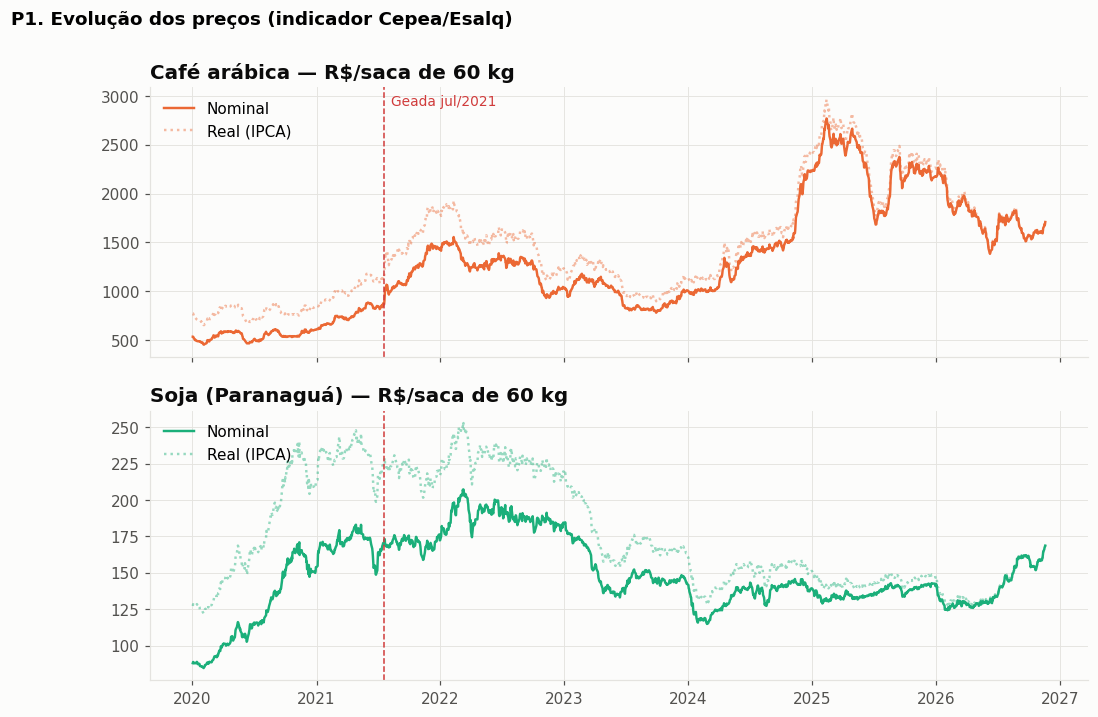

In [3]:
graficos.p1_evolucao(df);

In [4]:
estatistica.resumo_evolucao(df)

,ano,mean,min,max,variacao_ano_pct,produto
0,2020,543.44,452.94,610.57,13.52,cafe
1,2021,965.98,611.28,1487.58,132.48,cafe
2,2022,1260.07,930.62,1555.19,-26.63,cafe
3,2023,953.38,779.90,1179.20,-2.11,cafe
4,2024,1375.99,962.99,2236.76,122.05,cafe
5,2025,2270.40,1682.70,2769.45,-3.00,cafe
6,2026,1749.29,1383.57,2266.21,-21.31,cafe
7,2020,121.48,84.73,170.97,74.73,soja
8,2021,170.10,148.74,183.02,11.40,soja
9,2022,188.87,174.46,207.14,5.44,soja


## P2. Existe sazonalidade (safra × entressafra)?
Preço real dividido pela média do próprio ano (remove a tendência). Kruskal-Wallis testa se as distribuições diferem entre meses.

09:52:01 INFO    matplotlib.category: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


09:52:01 INFO    matplotlib.category: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


09:52:01 INFO    matplotlib.category: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


09:52:01 INFO    matplotlib.category: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


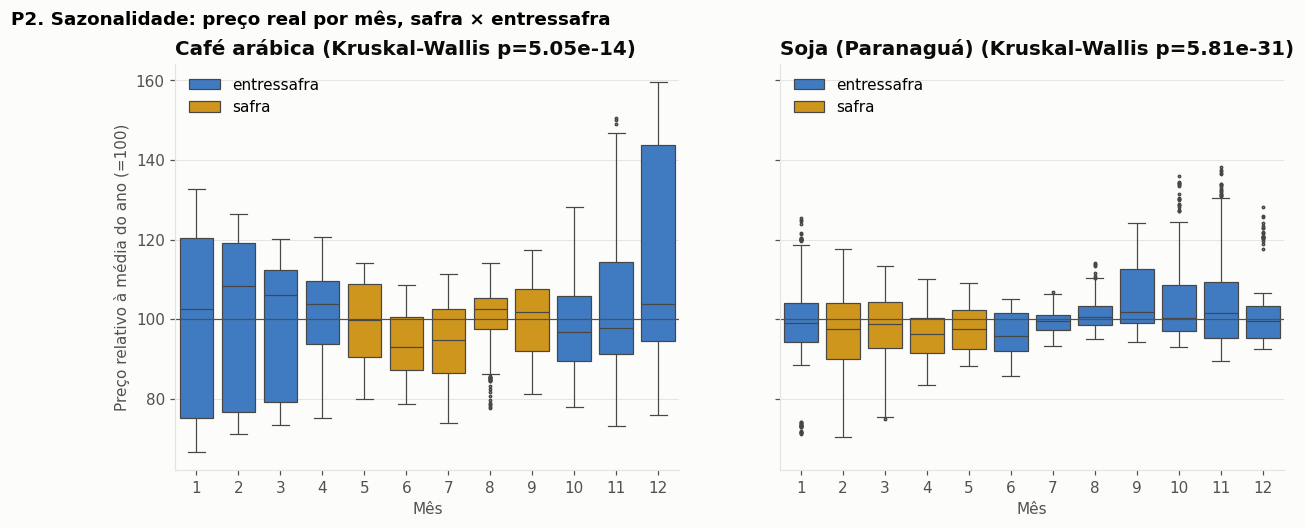

In [5]:
graficos.p2_sazonalidade(df);

In [6]:
for p in config.COMMODITIES:
    tabela, pval = estatistica.sazonalidade(df, p)
    print(p, "Kruskal-Wallis p =", f"{pval:.3g}")
    display(tabela)

cafe Kruskal-Wallis p = 5.05e-14


,mes,mean,median,std,periodo
0,1,99.77,102.65,20.75,entressafra
1,2,100.84,108.25,19.77,entressafra
2,3,99.84,105.97,15.61,entressafra
3,4,100.70,103.81,12.48,entressafra
4,5,98.88,99.75,9.93,safra
5,6,93.81,92.98,7.58,safra
6,7,93.94,94.84,9.66,safra
7,8,99.42,102.43,9.02,safra
8,9,99.58,101.83,9.30,safra
9,10,98.71,96.87,12.29,entressafra


soja Kruskal-Wallis p = 5.81e-31


,mes,mean,median,std,periodo
0,1,98.31,99.01,13.48,entressafra
1,2,96.41,97.42,12.70,safra
2,3,97.50,98.66,10.05,safra
3,4,96.03,96.30,6.65,safra
4,5,97.53,97.46,5.48,safra
5,6,96.49,95.87,5.42,entressafra
6,7,99.48,99.43,2.87,entressafra
7,8,101.61,100.55,4.30,entressafra
8,9,104.38,101.83,7.40,entressafra
9,10,104.85,100.35,11.54,entressafra


## P3. Os preços acompanham o dólar? Com que defasagem?
Índice base 100 (um único eixo, em vez de eixo duplo) e correlação cruzada entre as **variações** do preço e do dólar defasado.

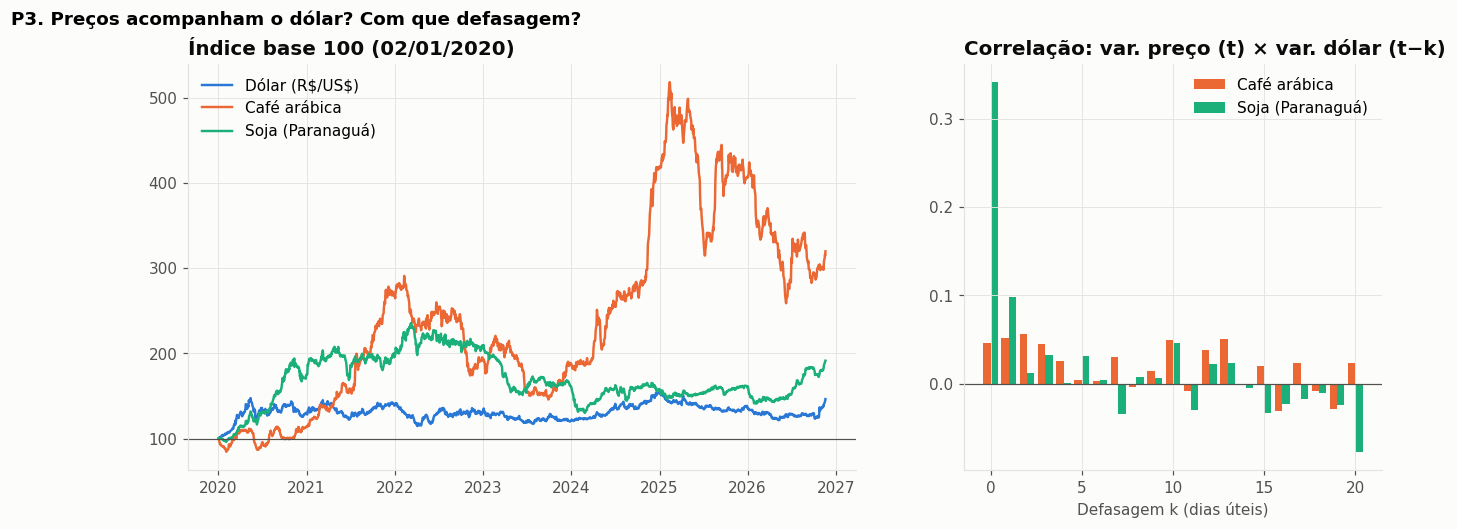

In [7]:
graficos.p3_dolar(df);

In [8]:
for p in config.COMMODITIES:
    cc = estatistica.correlacao_cruzada(df, p)
    print(p, "- defasagem de maior correlação:", cc.loc[cc["correlacao"].abs().idxmax()].to_dict())
pd.DataFrame([estatistica.repasse_cambial(df, p) for p in config.COMMODITIES])

cafe - defasagem de maior correlação: {'defasagem': 2.0, 'correlacao': 0.056310527370495876, 'p_valor': 0.019339965209330772, 'n': 1725.0}
soja - defasagem de maior correlação: {'defasagem': 0.0, 'correlacao': 0.34120515412907443, 'p_valor': 2.4279627783874352e-48, 'n': 1727.0}


,produto,elasticidade,r2,p_valor,meses
0,cafe,0.55999,0.053471,0.036598,82
1,soja,0.51745,0.136787,0.000627,82


## P4. Pouca chuva ou temperaturas extremas são seguidas de alta no café?

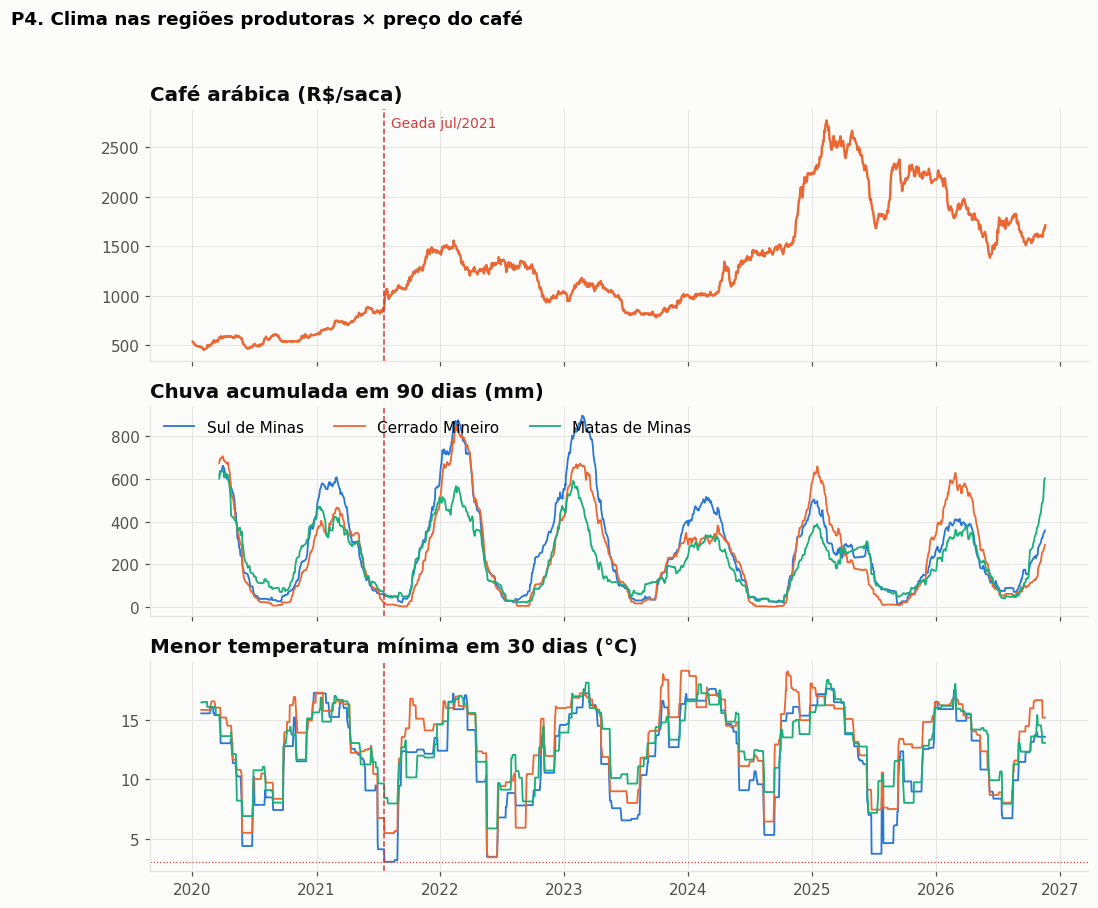

In [9]:
graficos.p4_clima(df);

In [10]:
estatistica.clima_vs_preco_futuro(df, 'cafe').head(10)

,variavel_clima,spearman,p_valor,n
11,temp_max_30d_cerrado_mineiro,0.340735,4.455685e-46,1648
9,chuva_90d_cerrado_mineiro,-0.262257,9.535290e-27,1611
7,temp_max_30d_sul_de_minas,0.236937,1.836560e-22,1648
3,temp_max_30d,0.234455,5.142399e-22,1648
1,chuva_90d,-0.194719,3.144849e-15,1611
5,chuva_90d_sul_de_minas,-0.176134,1.081029e-12,1611
8,chuva_30d_cerrado_mineiro,-0.139061,1.440165e-08,1648
13,chuva_90d_matas_de_minas,-0.105766,2.101641e-05,1611
15,temp_max_30d_matas_de_minas,0.099120,5.560630e-05,1648
4,chuva_30d_sul_de_minas,-0.096180,9.206989e-05,1648


## P5. Impacto da geada de julho de 2021
A soja, pouco exposta ao clima de MG, funciona como grupo de controle.

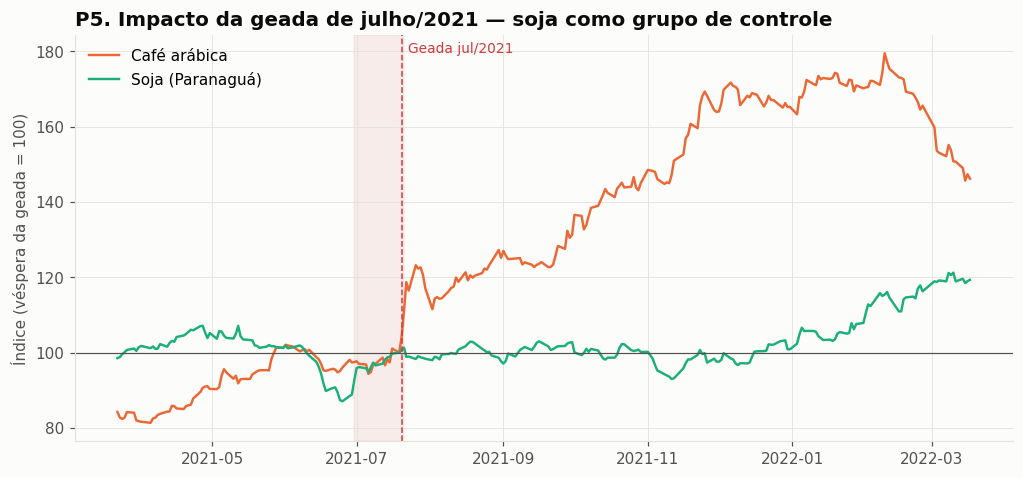

In [11]:
graficos.p5_geada(df);

In [12]:
estatistica.impacto_geada(df)

,produto,media_30d_antes,media_30d_depois,var_30d_pct,maximo_30d,media_90d_depois,var_90d_pct,maximo_90d,media_180d_depois,var_180d_pct,maximo_180d
0,cafe,839.98,1015.52,20.9,1067.27,1078.14,28.4,1242.78,1234.03,46.9,1502.91
1,soja,161.10,170.53,5.9,175.83,171.25,6.3,175.95,170.94,6.1,182.14


## P6. Qual commodity é mais sensível ao clima e qual ao câmbio?

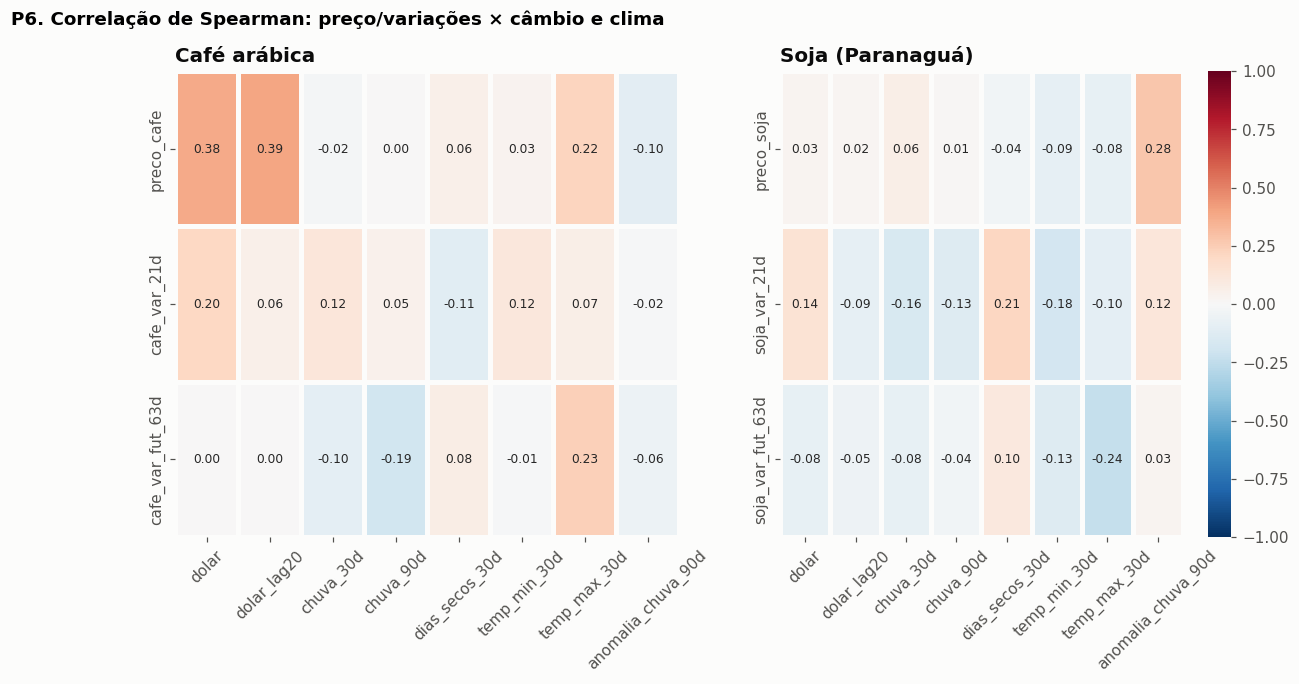

In [13]:
graficos.p6_correlacoes(df);

In [14]:
estatistica.sensibilidade(df)

,produto,corr_diaria_dolar_t0,elasticidade_cambio_mensal,r2_cambio_mensal,max_abs_spearman_clima,variavel_clima_mais_associada
0,cafe,0.046,0.560,0.053,0.341,temp_max_30d_cerrado_mineiro
1,soja,0.341,0.517,0.137,0.302,temp_max_30d_matas_de_minas


> Lembrete: as relações indicam **correlação**, não causalidade — estoques mundiais, demanda internacional e produção de outros países não estão no estudo.